# 1 · Resolver Blackjack con Q-learning

*Secciones del video 0:14 – 1:09 (Blackjack rules → Summary of Solving Blackjack).*

## Reglas (versión de Gymnasium)
- Juegas contra el dealer. Figuras valen 10, el As vale 11 o 1 (si vale 11 sin pasarte, es un **as usable**).
- Acciones: **0 = stick** (plantarse) o **1 = hit** (pedir carta).
- Si pasas de 21 pierdes. Si te plantas, el dealer pide hasta tener ≥ 17.
- Recompensa: **+1** ganar, **0** empate, **−1** perder. Solo llega al final de la mano.
- Observación: `(suma_jugador, carta_visible_dealer, as_usable)`.

## Por qué es buen primer problema
El espacio de estados es pequeño (~ 32×11×2), así que podemos guardar **una tabla**
con el valor de cada par (estado, acción). Eso es Q-learning *tabular*.

In [1]:
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from tqdm.auto import tqdm

env = gym.make("Blackjack-v1", sab=True)
obs, info = env.reset(seed=0)
print(obs)

(11, 10, 0)


C:\Users\omarr\AppData\Local\Claude-Data\claude_pzs8sxrjxfjjc\scratch-workspaces\badbd98c-2f80-4347-a53f-2b8362480b89\78181cbf-fd6e-481d-8c43-859b04d5d4af\scratch-2026-11-09-5c3ae4\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Ejecutar una acción
Probemos pedir carta una vez y ver qué devuelve el entorno.

In [2]:
obs, reward, terminated, truncated, info = env.step(1)
print(obs, reward, terminated)

(12, 10, 0) 0.0 False


## Los valores Q
$Q(s,a)$ = recompensa total esperada si estoy en el estado $s$, tomo la acción $a$, y de ahí
en adelante juego bien. Si conociera $Q$ exacto, la mejor política sería trivial:
$\pi(s) = \arg\max_a Q(s,a)$.

### Regla de actualización de Q-learning (diferencia temporal, TD)
Después de cada paso $(s, a, r, s')$:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,\Big[\underbrace{r + \gamma \max_{a'} Q(s',a')}_{\text{objetivo TD}} - Q(s,a)\Big]$$

- $\alpha$ = tasa de aprendizaje (qué tanto le creo a la nueva experiencia)
- $\gamma$ = factor de descuento (qué tanto valen las recompensas futuras)
- El corchete es el **error TD**: la "sorpresa". Si es 0, $Q$ ya es consistente.
- Si el episodio *terminó*, no hay futuro: el objetivo es solo $r$.

Es **model-free**: nunca usamos las probabilidades de las cartas, solo experiencia.
(Esto es exactamente lo del video 3 de Brunton, *Q-Learning and TD learning*.)

## Exploración vs. explotación: ε-greedy
Si siempre elijo el argmax de un $Q$ todavía malo, nunca descubro acciones mejores.
Con probabilidad $\varepsilon$ elijo al azar (explorar); si no, el argmax (explotar).
Empezamos con $\varepsilon = 1$ y lo bajamos poco a poco.

In [3]:
class Agente:
    def __init__(self, lr, epsilon, epsilon_decay, epsilon_final, gamma=0.95):
        self.q = defaultdict(lambda: np.zeros(2))
        self.lr = lr
        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.epsilon_final = epsilon_final
        self.gamma = gamma
        self.errores = []

    def accion(self, obs):
        if np.random.random() < self.epsilon:
            return np.random.randint(2)
        return int(np.argmax(self.q[obs]))

    def actualizar(self, obs, accion, reward, terminated, next_obs):
        futuro = 0 if terminated else np.max(self.q[next_obs])
        error = reward + self.gamma * futuro - self.q[obs][accion]
        self.q[obs][accion] += self.lr * error
        self.errores.append(error)

    def bajar_epsilon(self):
        self.epsilon = max(self.epsilon_final, self.epsilon - self.epsilon_decay)

## Hiperparámetros (los mismos del curso / tutorial oficial de Gymnasium)
ε baja de 1 a 0.1 durante la primera mitad del entrenamiento.

In [4]:
n_episodios = 100_000
agente = Agente(lr=0.01, epsilon=1.0, epsilon_decay=1.0 / (n_episodios / 2), epsilon_final=0.1)

np.random.seed(0)
env = gym.make("Blackjack-v1", sab=True)
env.reset(seed=0)

((11, 10, 0), {})

## Entrenamiento
Cada episodio = una mano. Jugamos, actualizamos Q en cada paso, y bajamos ε al final.

In [5]:
recompensas = []

for episodio in tqdm(range(n_episodios)):
    obs, info = env.reset()
    done = False
    while not done:
        accion = agente.accion(obs)
        next_obs, reward, terminated, truncated, info = env.step(accion)
        agente.actualizar(obs, accion, reward, terminated, next_obs)
        obs = next_obs
        done = terminated or truncated
    recompensas.append(reward)
    agente.bajar_epsilon()

  0%|          | 0/100000 [00:00<?, ?it/s]

  1%|▏         | 1298/100000 [00:00<00:07, 12887.10it/s]

  3%|▎         | 2613/100000 [00:00<00:07, 12968.94it/s]

  4%|▍         | 4007/100000 [00:00<00:07, 13396.84it/s]

  5%|▌         | 5347/100000 [00:00<00:07, 12923.89it/s]

  7%|▋         | 6827/100000 [00:00<00:06, 13542.72it/s]

... (65 outputs left out)

 97%|█████████▋| 96845/100000 [00:07<00:00, 13595.76it/s]

 98%|█████████▊| 98210/100000 [00:07<00:00, 13432.33it/s]

100%|█████████▉| 99686/100000 [00:07<00:00, 13790.62it/s]

100%|██████████| 100000/100000 [00:07<00:00, 12970.08it/s]

## Visualizar el entrenamiento
Usamos promedios móviles porque cada mano es muy ruidosa (±1).
- **Recompensa**: debería subir y estabilizarse (Blackjack favorece a la casa, así que < 0).
- **Error TD**: debería acercarse a 0: Q se vuelve consistente consigo mismo.

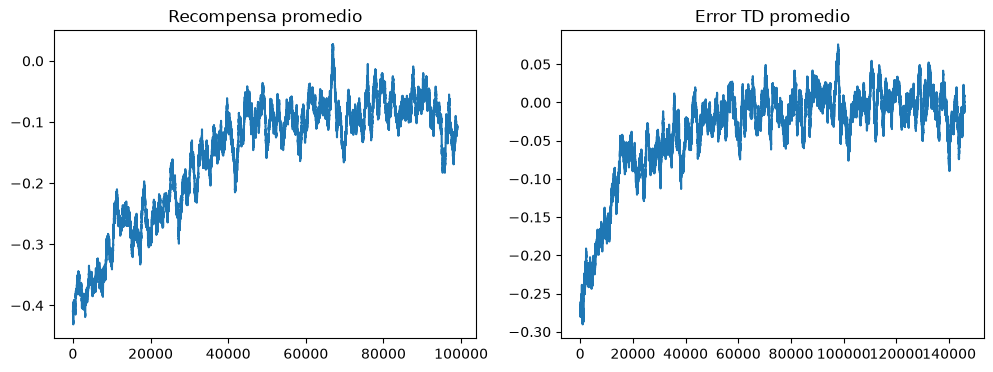

In [6]:
def promedio_movil(x, w=1000):
    return np.convolve(x, np.ones(w) / w, mode="valid")

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(promedio_movil(recompensas))
axs[0].set_title("Recompensa promedio")
axs[1].plot(promedio_movil(agente.errores))
axs[1].set_title("Error TD promedio")
plt.show()

## La política aprendida
Para cada combinación (suma del jugador, carta del dealer) mostramos qué acción eligió el agente:
**verde = plantarse (S)**, **rojo = pedir (H)**. Separamos con / sin as usable,
porque cambian mucho la estrategia.

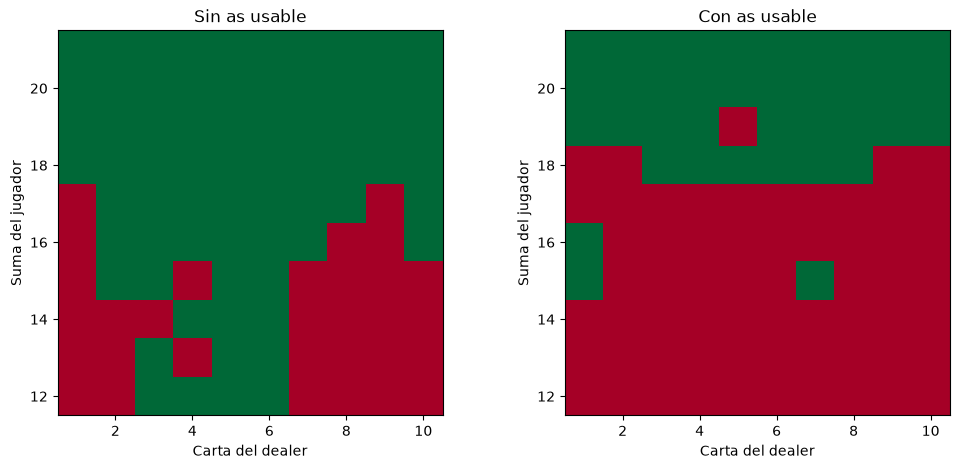

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

for k, as_usable in enumerate([0, 1]):
    politica = np.zeros((10, 10))
    for i, jugador in enumerate(range(12, 22)):
        for j, dealer in enumerate(range(1, 11)):
            politica[i, j] = np.argmax(agente.q[(jugador, dealer, as_usable)])

    axs[k].imshow(politica, origin="lower", cmap="RdYlGn_r", extent=[0.5, 10.5, 11.5, 21.5])
    axs[k].set_title("Con as usable" if as_usable else "Sin as usable")
    axs[k].set_xlabel("Carta del dealer")
    axs[k].set_ylabel("Suma del jugador")

plt.show()

Lo que deberías ver (y coincide con la "estrategia básica" de casino):
- **Sin as usable**: pedir con 12–16 cuando el dealer muestra 7 o más; plantarse con 13–16
  cuando el dealer muestra 2–6 (es probable que él se pase). Siempre plantarse con 17+.
- **Con as usable**: se puede pedir más agresivamente porque el As amortigua (11 → 1).
Algunas casillas raras son ruido: estados poco visitados o donde ambas acciones valen casi igual.

## Evaluación: ¿qué tan bien juega?
Apagamos la exploración (ε = 0) y jugamos 50,000 manos. Comparamos con jugar al azar
y con la regla simple "plantarse con 17 o más".

In [8]:
def evaluar(politica, n=50_000):
    env = gym.make("Blackjack-v1", sab=True)
    resultados = []
    for i in range(n):
        obs, info = env.reset(seed=i)
        done = False
        while not done:
            obs, reward, terminated, truncated, info = env.step(politica(obs))
            done = terminated or truncated
        resultados.append(reward)
    return np.mean(resultados)

print("Aleatoria:      ", evaluar(lambda obs: np.random.randint(2)))
print("Plantarse en 17:", evaluar(lambda obs: int(obs[0] < 17)))
print("Q-learning:     ", evaluar(lambda obs: int(np.argmax(agente.q[obs]))))

Aleatoria:       -0.39494


Plantarse en 17: -0.07602


Q-learning:      -0.05694


## Resumen (lo que dice el video en 1:04)
- Blackjack es un MDP pequeño → Q-learning **tabular** basta.
- El agente nunca vio las reglas de probabilidad: aprendió solo jugando (model-free).
- ε-greedy equilibra explorar y explotar; ε decae con el tiempo.
- La recompensa media queda negativa: **la casa siempre gana**, pero el agente pierde
  mucho menos que al azar (≈ −0.39) y que la regla simple "plantarse con 17" (≈ −0.08).
  Le queda ≈ −0.05 por mano, cerca de la estrategia básica óptima.

**Limitación**: la tabla solo funciona si los estados son pocos y discretos. En CartPole
el estado es continuo (4 números reales) → no cabe en una tabla → necesitamos
**aproximar** Q con una red neuronal. Eso es DQN (notebook 2).